In [ ]:
import pandas as pd

#for machine learing
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

# for nlp

import nltk
import re
import string
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.utils import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer
from nltk import pos_tag
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import SMOTE

from sklearn.preprocessing import OneHotEncoder, LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report,roc_auc_score,roc_curve
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# **LOADING DATA**

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/ict/Preprocessed_DonorsChoose_dataset.csv")

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

df.head()

,id,teacher_prefix,school_state,project_grade_category,project_subject_categories,project_subject_subcategories,teacher_number_of_previously_posted_projects,project_is_approved,price,quantity,cleaned_titles,cleaned_essays,cleaned_summary,isdigit_summary
0,p253737,mrs,in,grades_prek_2,literacy_language,esl_literacy,0,0,154.60,23,educational support english learners home,students english learners working english seco...,students_need_opportunities_practice_beginning...,0
1,p258326,mr,fl,grades_6_8,history_civics_health_sports,civics_government_teamsports,7,1,299.00,1,wanted projector hungry learners,students arrive school eager learn polite gene...,students_need_projector_help_viewing_education...,0
2,p182444,ms,az,grades_6_8,health_sports,health_wellness_teamsports,1,0,516.85,22,soccer equipment awesome middle school students,true champions not always ones win guts mia ha...,students_need_shine_guards_athletic_socks_socc...,0
3,p246581,mrs,ky,grades_prek_2,literacy_language_math_science,literacy_mathematics,4,1,232.90,4,techie kindergarteners,work unique school filled esl english second l...,students_need_engage_reading_math_way_inspire_...,0
4,p104768,mrs,tx,grades_prek_2,math_science,mathematics,1,1,67.98,4,interactive math tools,second grade classroom next year made around 2...,students_need_hands_practice_mathematics_fun_p...,0


In [ ]:
df.describe()

,teacher_number_of_previously_posted_projects,project_is_approved,price,quantity,isdigit_summary
count,109248.000000,109248.000000,109248.000000,109248.000000,109248.000000
mean,11.153165,0.848583,298.119343,16.965610,0.144222
std,27.777154,0.358456,367.498030,26.182942,0.351317
min,0.000000,0.000000,0.660000,1.000000,0.000000
25%,0.000000,1.000000,104.310000,4.000000,0.000000
50%,2.000000,1.000000,206.220000,9.000000,0.000000
75%,9.000000,1.000000,379.000000,21.000000,0.000000
max,451.000000,1.000000,9999.000000,930.000000,1.000000


In [ ]:
df.tail()

,id,teacher_prefix,school_state,project_grade_category,project_subject_categories,project_subject_subcategories,teacher_number_of_previously_posted_projects,project_is_approved,price,quantity,cleaned_titles,cleaned_essays,cleaned_summary,isdigit_summary
109243,p048540,mr,mo,grades_prek_2,literacy_language_math_science,literature_writing_mathematics,0,1,59.98,8,privacy shields help promote independent thinking,welcome mr ramos 2nd grade classroom title 1 s...,students_need_privacy_partitions_help_focus_be...,0
109244,p166281,ms,nj,grades_prek_2,literacy_language_math_science,literacy_mathematics,0,1,846.32,4,technology classroom,every morning start day core values lead solel...,students_need_two_ipad_protective_cases_enhanc...,0
109245,p155633,mrs,nj,grades_prek_2,literacy_language_math_science,literacy_mathematics,3,1,239.96,4,2016 2017 beginning year basics,great group sharing caring students multi grad...,students_need_giant_comfy_pillows_order_help_r...,0
109246,p206114,mrs,ny,grades_3_5,health_sports_specialneeds,health_wellness_specialneeds,0,1,73.05,16,flexible seating inclusive classroom,students live small rural community classroom ...,students_need_flexible_seating_options_bean_ba...,0
109247,p191189,ms,va,grades_6_8,appliedlearning_math_science,college_careerprep_mathematics,0,1,109.90,5,classroom tech develop 21st century leaders,last time used math probably within last hour ...,students_need_opportunities_work_technology_or...,1


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.isna().sum()

,0
id,0
teacher_prefix,0
school_state,0
project_grade_category,0
project_subject_categories,0
project_subject_subcategories,0
teacher_number_of_previously_posted_projects,0
project_is_approved,0
price,0
quantity,0


In [ ]:
(df.isna().sum()/len(df)*100)

,0
id,0.00000
teacher_prefix,0.00000
school_state,0.00000
project_grade_category,0.00000
project_subject_categories,0.00000
project_subject_subcategories,0.00000
teacher_number_of_previously_posted_projects,0.00000
project_is_approved,0.00000
price,0.00000
quantity,0.00000


In [ ]:
df = df.dropna(subset="cleaned_titles")

In [ ]:
(df.isna().sum()/len(df)*100)

,0
id,0.0
teacher_prefix,0.0
school_state,0.0
project_grade_category,0.0
project_subject_categories,0.0
project_subject_subcategories,0.0
teacher_number_of_previously_posted_projects,0.0
project_is_approved,0.0
price,0.0
quantity,0.0


In [ ]:
# there is no missing value

In [ ]:
df.info()# to check summary

<class 'pandas.core.frame.DataFrame'>
Index: 109205 entries, 0 to 109247
Data columns (total 14 columns):
 #   Column                                        Non-Null Count   Dtype  
---  ------                                        --------------   -----  
 0   id                                            109205 non-null  object 
 1   teacher_prefix                                109205 non-null  object 
 2   school_state                                  109205 non-null  object 
 3   project_grade_category                        109205 non-null  object 
 4   project_subject_categories                    109205 non-null  object 
 5   project_subject_subcategories                 109205 non-null  object 
 6   teacher_number_of_previously_posted_projects  109205 non-null  int64  
 7   project_is_approved                           109205 non-null  int64  
 8   price                                         109205 non-null  float64
 9   quantity                                      109205 

In [ ]:
df.shape

(109205, 14)

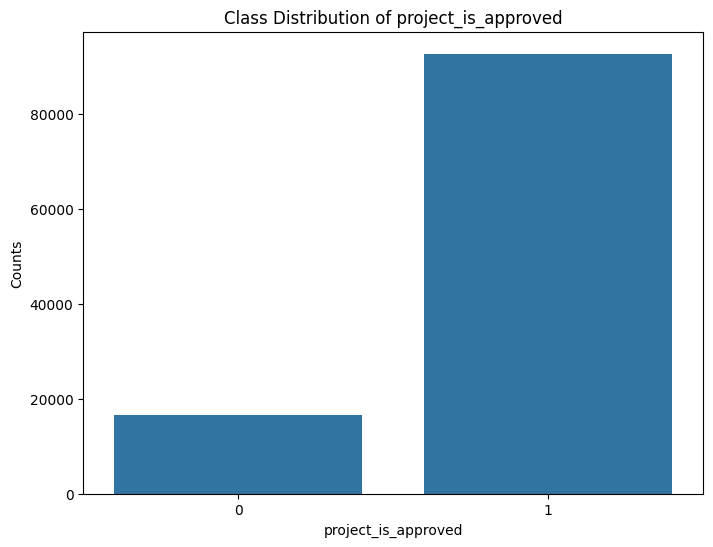

In [ ]:
# Checking the class imbalance

values_grade = df['project_is_approved'].value_counts()

plt.figure(figsize=(8, 6))
sns.barplot(x=values_grade.index, y=values_grade.values)

plt.xlabel("project_is_approved")
plt.ylabel("Counts")
plt.title("Class Distribution of project_is_approved")
plt.show()

# NLP Preprocessing Pipeline

##lowering

In [ ]:
text_columns = ['cleaned_titles', 'cleaned_essays', 'cleaned_summary']
for col in text_columns:
  df.loc[:,col] = df[col].str.lower()

## punctuation,html,email,special charater

In [ ]:
# check again if the text is cleaned or not
def check_pattern(serial):
    patterns = {
        "email":        r"[\w.+-]+@[\w-]+.[\w.-]+",
        "number":       r"\d+(?:.\d+)?",
        "html_tag":     r"<[^>]+>",
        "special_char": r"[^A-Za-z0-9\s']",
    }
    for col in text_columns:
      print(f"checking the columns:{col}")
      for name, pattern in patterns.items():
        has_match = df[col].str.contains(pattern, regex=True)
        print(f"{name} --> {has_match.sum()} reviews out of {len(serial)}")

check_pattern(df[text_columns])

checking the columns:cleaned_titles
email --> 0 reviews out of 109205
number --> 6354 reviews out of 109205
html_tag --> 0 reviews out of 109205
special_char --> 0 reviews out of 109205
checking the columns:cleaned_essays
email --> 0 reviews out of 109205
number --> 72079 reviews out of 109205
html_tag --> 0 reviews out of 109205
special_char --> 0 reviews out of 109205
checking the columns:cleaned_summary
email --> 0 reviews out of 109205
number --> 15750 reviews out of 109205
html_tag --> 0 reviews out of 109205
special_char --> 109205 reviews out of 109205


In [ ]:
# remove html,email,special characters

def clean(text):
    text = re.sub(r"<[^>]+>", " ", text)              # 1. HTML tags
    text = re.sub(r"[\w.+-]+@[\w-]+.[\w.-]+", " ", text)  # 2. emails
    text = re.sub(r"[^A-Za-z0-9\s']", " ", text)         # 3. special characters
    return re.sub(r"\s+", " ", text).strip().lower()  # 4. extra spaces and normalize to lowercase


for col in text_columns:
    df.loc[:,col] = df[col].apply(clean)

In [ ]:
# check again if the text is cleaned or not

check_pattern(df[text_columns])

checking the columns:cleaned_titles
email --> 0 reviews out of 109205
number --> 6354 reviews out of 109205
html_tag --> 0 reviews out of 109205
special_char --> 0 reviews out of 109205
checking the columns:cleaned_essays
email --> 0 reviews out of 109205
number --> 72079 reviews out of 109205
html_tag --> 0 reviews out of 109205
special_char --> 0 reviews out of 109205
checking the columns:cleaned_summary
email --> 0 reviews out of 109205
number --> 15750 reviews out of 109205
html_tag --> 0 reviews out of 109205
special_char --> 0 reviews out of 109205


## tokenize

In [ ]:
from nltk.tokenize.sonority_sequencing import punctuation
#remove puntuations
def remove_punc(text):
  punctuation = string.punctuation
  for punt in punctuation:
    text = text.replace(punt,'')
  return text

df[text_columns] = df[text_columns].apply(remove_punc)

#check if text contains punctuations
for col in text_columns:
    print("!" in df[col].iloc[1])

False
False
False


In [ ]:
# word tokenization

nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [ ]:
def tokenize(text):
  return word_tokenize(text)


for col in text_columns:
  df[col] = df[col].apply(tokenize)

## lemmatizer

In [ ]:
#treati the tokenzied data to lemattize
lematizer =WordNetLemmatizer()
# download required resource
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('averaged_perceptron_tagger_eng')

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.


True

In [ ]:
def get_wordnet_pos(tag):
  if tag.startswith('J'):
    return 'a'
  elif tag.startswith('V'):
    return 'v'
  elif tag.startswith('N'):
    return 'n'
  elif tag.startswith('R'):
    return 'r'
  return 'n'
#lematize tokens using dynamic POS



def lematize_tokens(tokens):
  tagged_words = pos_tag(tokens)

  lematize_words = [
      lematizer.lemmatize(word, get_wordnet_pos(tag))
      for word , tag in tagged_words
  ]
  return lematize_words
# apply to tokenized data
for col in text_columns:
  df[col] = df[col].map(lematize_tokens)

df[text_columns].head()

,cleaned_titles,cleaned_essays,cleaned_summary
0,"[educational, support, english, learner, home]","[student, english, learner, work, english, sec...","[student, need, opportunity, practice, begin, ..."
1,"[want, projector, hungry, learner]","[student, arrive, school, eager, learn, polite...","[student, need, projector, help, view, educati..."
2,"[soccer, equipment, awesome, middle, school, s...","[true, champion, not, always, one, win, gut, m...","[student, need, shine, guard, athletic, sock, ..."
3,"[techie, kindergartener]","[work, unique, school, fill, esl, english, sec...","[student, need, engage, read, math, way, inspi..."
4,"[interactive, math, tool]","[second, grade, classroom, next, year, make, a...","[student, need, hand, practice, mathematics, f..."


# TF - IDF

In [ ]:
from numpy import vectorize
from sklearn.feature_extraction.text import TfidfVectorizer
from nltk.util import  ngrams


In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

# Dictionary to store the Count Vectorizer (Bag of Words) sparse matrices for each column
count_matrices = {}

for col in text_columns:
  # 1. Join tokenized lists back into space-separated strings
  corpus = df[col].apply(
      lambda x: ' '.join(x) if isinstance(x, list) else str(x)
  )

  # 2. Initialize CountVectorizer with uni-grams, bi-grams, and tri-grams
  countvect = CountVectorizer(min_df=3, ngram_range=(1, 3))

  # 3. Fit and transform, keeping it sparse to save RAM
  count_matrices[col] = countvect.fit_transform(corpus)

# Access your Bag of Words sparse matrices like this:
# count_matrices['cleaned_titles']
# count_matrices['cleaned_essays']
# count_matrices['cleaned_summary']

In [ ]:
# Access your Bag of Words sparse matrices like this:
count_matrices['cleaned_titles']
count_matrices['cleaned_essays']
count_matrices['cleaned_summary']

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 2617960 stored elements and shape (109205, 111304)>

In [ ]:
# View sample n-gram features learned for each column
for col, mat in count_matrices.items():
  # Get the vectorizer's feature names (which already include your 1-to-3 grams)
  # Let's inspect the first 10 n-gram features for each column
  print(f"--- Top n-grams for {col} ---")
  # To get the vectorizer back, or if you want to inspect feature names:
  # (Note: we can fit a quick vectorizer or inspect the column names if converted,
  # but here we can just see total feature count)
  print(f"Total unique n-gram features: {mat.shape[1]}")

--- Top n-grams for cleaned_titles ---
Total unique n-gram features: 27670
--- Top n-grams for cleaned_essays ---
Total unique n-gram features: 1396667
--- Top n-grams for cleaned_summary ---
Total unique n-gram features: 111304


In [ ]:
#Pre-trained Word2Vec: Use a widely available pre-trained model (e.g., Google News vectors or similar). Map words to embeddings and compute document-level representations (e.g., averaging, TF-IDF-weighted averaging).


# word2vec

In [ ]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 53.4 MB/s  0:00:00


In [ ]:
import gensim.downloader as api

In [ ]:
# check available pretrained models
print(api.info()["models"].keys())

In [ ]:
word2vec_model = api.load("word2vec-google-news-300")
print("model  loaded sucessfully")

In [ ]:
print(word2vec_model["student"].shape)

In [ ]:
#compare similarity between words

print(word2vec_model.similarity("king","queen"))
print(word2vec_model.similarity("king","prince"))
print(word2vec_model.similarity("king","kingdom"))
print(word2vec_model.similarity("computer","laptop"))

In [ ]:
#related words connected with king

print(word2vec_model.most_similar("king",topn=5))

In [ ]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. Standard Mean Word2Vec Embeddings
def get_document_embedding(tokens, model, vector_size=300):
    if not isinstance(tokens, list) or len(tokens) == 0:
        return np.zeros(vector_size)
    vectors = [model[word] for word in tokens if word in model]
    if len(vectors) == 0:
        return np.zeros(vector_size)
    return np.mean(vectors, axis=0)

word2vec_embeddings = {}
vector_size = word2vec_model.vector_size

for col in text_columns:
    print(f"Computing standard Word2Vec embeddings for {col}...")
    word2vec_embeddings[col] = np.vstack(
        df[col].apply(lambda tokens: get_document_embedding(tokens, word2vec_model, vector_size))
    )


# 2. TF-IDF Weighted Word2Vec Embeddings
def get_tfidf_weighted_embedding(tokens, tfidf_vectorizer, tfidf_vector, model, vector_size=300):
    if not isinstance(tokens, list) or len(tokens) == 0:
        return np.zeros(vector_size)

    feature_index_map = tfidf_vectorizer.vocabulary_
    weighted_sum = np.zeros(vector_size)
    total_weight = 0.0

    for word in tokens:
        if word in model and word in feature_index_map:
            idx = feature_index_map[word]
            weight = tfidf_vector[0, idx]
            if weight > 0:
                weighted_sum += weight * model[word]
                total_weight += weight

    if total_weight == 0:
        return get_document_embedding(tokens, model, vector_size)

    return weighted_sum / total_weight

tfidf_word2vec_embeddings = {}

for col in text_columns:
    print(f"Computing TF-IDF weighted Word2Vec embeddings for {col}...")
    corpus = df[col].apply(lambda x: " ".join(x) if isinstance(x, list) else str(x))

    # Fit TF-IDF on this text column
    tfidf_vect = TfidfVectorizer(min_df=3)
    tfidf_matrix = tfidf_vect.fit_transform(corpus)

    embeddings_list = []
    for i, tokens in enumerate(df[col]):
        row_vec = tfidf_matrix[i:i+1]
        emb = get_tfidf_weighted_embedding(tokens, tfidf_vect, row_vec, word2vec_model, vector_size)
        embeddings_list.append(emb)

    tfidf_word2vec_embeddings[col] = np.vstack(embeddings_list)

print("\nAll document representations generated successfully!")
print("Shape of cleaned_titles (Standard):", word2vec_embeddings['cleaned_titles'].shape)
print("Shape of cleaned_titles (TF-IDF Weighted):", tfidf_word2vec_embeddings['cleaned_titles'].shape)

In [ ]:
from gensim.models import Word2Vec

# 1. Prepare your training corpus from all text columns
tokenize_corpus = []
for col in text_columns:
  tokenize_corpus.extend(df[col].dropna().tolist())

# 2. Train CBOW Word2Vec model
model_cbow = Word2Vec(
    sentences=tokenize_corpus,
    vector_size=100,  # embedding dimension
    window=5,  # context window
    min_count=1,  # ignore words with freq < 1
    sg=0,  # cbow (0 for CBOW, 1 for Skip-gram)
    workers=4,  # number of cpu cores
    epochs=50,  # training iterations
)

print("CBOW Word2Vec model trained successfully!")

In [ ]:
# display th word vector

print("shape :",model_cbow.wv['king'].shape)

# calculate loss

In [ ]:
from gensim.models.callbacks import CallbackAny2Vec
# word2vec : cbow loss

# genism class that allow u to excute
# your own code at specific points during word2vec training
# to capture loss at each points

class LossLogger(CallbackAny2Vec):
    def __init__(self):
        self.epoch = 0
        self.losses = []
        self.previous_loss = 0

    def on_epoch_end(self, model):
        cumulative_loss = model.get_latest_training_loss()
        epoch_loss = cumulative_loss - self.previous_loss
        self.losses.append(epoch_loss)
        print(f"epoch {self.epoch + 1}: loss = {epoch_loss}")
        self.previous_loss = cumulative_loss
        self.epoch += 1

loss_logger = LossLogger()

model_cbow = Word2Vec(
    sentences = tokenize_corpus,
    vector_size = 100,
    window = 5,
    min_count = 1,
    sg = 0,
    workers = 1,
    epochs = 100,
    compute_loss = True,
    callbacks = [loss_logger],
    seed = 42
)

# 4. Classical ML Models


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
import scipy.sparse as sp
import numpy as np

# 1. Combine all 3 text representations (using the sparse count/TF-IDF matrices)
X_combined_sparse = sp.hstack([
    count_matrices['cleaned_titles'],
    count_matrices['cleaned_essays'],
    count_matrices['cleaned_summary']
])

# Alternatively, if combining dense Word2Vec embeddings:
# X_combined_dense = np.hstack([
#     word2vec_embeddings['cleaned_titles'],
#     word2vec_embeddings['cleaned_essays'],
#     word2vec_embeddings['cleaned_summary']
# ])

y = df['project_is_approved']

# 2. Train-test split (stratified to maintain class balance)
X_train, X_test, y_train, y_test = train_test_split(
    X_combined_sparse, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Combined Training set shape: {X_train.shape}")
print(f"Combined Test set shape: {X_test.shape}")

# 3. Model 1: Logistic Regression
print("\n--- Training Logistic Regression (All 3 Columns) ---")
lr_model = LogisticRegression(max_iter=1000, random_state=42, n_jobs=-1)
lr_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_test)
print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_lr))
print("\nClassification Report:\n", classification_report(y_test, y_pred_lr))

# 4. Model 2: Random Forest Classifier (using dense Word2Vec embeddings concatenated)
X_combined_dense = np.hstack([
    word2vec_embeddings['cleaned_titles'],
    word2vec_embeddings['cleaned_essays'],
    word2vec_embeddings['cleaned_summary']
])

X_train_w2v, X_test_w2v, y_train_w2v, y_test_w2v = train_test_split(
    X_combined_dense, y, test_size=0.2, random_state=42, stratify=y
)

print("\n--- Training Random Forest (All 3 Word2Vec Columns) ---")
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train_w2v, y_train_w2v)

y_pred_rf = rf_model.predict(X_test_w2v)
print("Random Forest Accuracy:", accuracy_score(y_test_w2v, y_pred_rf))
print("\nClassification Report:\n", classification_report(y_test_w2v, y_pred_rf))

## from below i cant run the code due to ram crash and run time timing

In [ ]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

print("--- 4. Cross-Validation & Hyperparameter Tuning ---")

# 1. Use Stratified 3-Fold Cross-Validation to save memory and handle class balance securely
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# 2. Define a smaller hyperparameter grid to prevent long runtimes/crashes
param_grid = {
    'C': [0.1, 1.0],  # Regularization strength
    'solver': ['saga'] # Memory-efficient solver for large sparse matrices
}

# 3. Setup GridSearchCV with parallel jobs (-1)
grid_search = GridSearchCV(
    estimator=LogisticRegression(max_iter=500, random_state=42, n_jobs=-1),
    param_grid=param_grid,
    cv=cv,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

# Optional: Subsample X_train and y_train if your RAM crashes during GridSearch fit (e.g., use 50k rows)
# X_train_sample, _, y_train_sample, _ = train_test_split(X_train, y_train, train_size=50000, random_state=42, stratify=y_train)

# Fit Grid Search (using X_train and y_train from your previous split)
grid_search.fit(X_train, y_train)

print(f"\nBest Hyperparameters Found: {grid_search.best_params_}")
print(f"Best Cross-Validation F1-Score: {grid_search.best_score_:.4f}")

# 4. Evaluate Best Model on Test Set
best_model = grid_search.best_estimator_
y_pred_tuned = best_model.predict(X_test)

# 5. Report Performance Metrics
acc = accuracy_score(y_test, y_pred_tuned)
prec = precision_score(y_test, y_pred_tuned, zero_division=0)
rec = recall_score(y_test, y_pred_tuned, zero_division=0)
f1 = f1_score(y_test, y_pred_tuned, zero_division=0)

print("\n--- Test Set Performance Metrics ---")
print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-Score:  {f1:.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred_tuned, zero_division=0))

# 6. Plot Confusion Matrix (Crash-free matplotlib/seaborn block)
plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_tuned)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title("Confusion Matrix - Tuned Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

#  deep learing model

In [ ]:
import tensorflow as tf
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization, Concatenate
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ReduceLROnPlateau
import numpy as np

# 1. Prepare inputs for the Functional API model
# Using dense Word2Vec embeddings for titles and essays as multi-inputs
input_dim_1 = word2vec_embeddings['cleaned_titles'].shape[1]
input_dim_2 = word2vec_embeddings['cleaned_essays'].shape[1]

X_train_t, X_test_t, y_train_dl, y_test_dl = train_test_split(
    word2vec_embeddings['cleaned_titles'], y, test_size=0.2, random_state=42, stratify=y
)
X_train_e, X_test_e, _, _ = train_test_split(
    word2vec_embeddings['cleaned_essays'], y, test_size=0.2, random_state=42, stratify=y
)

# 2. Define Subnetworks using Functional API
# Input 1: Titles Word2Vec Embedding
input_titles = Input(shape=(input_dim_1,), name='titles_input')
x1 = Dense(128, activation='relu')(input_titles)
x1 = BatchNormalization()(x1)
x1 = Dropout(0.3)(x1)

# Input 2: Essays Word2Vec Embedding
input_essays = Input(shape=(input_dim_2,), name='essays_input')
x2 = Dense(128, activation='relu')(input_essays)
x2 = BatchNormalization()(x2)
x2 = Dropout(0.3)(x2)

# 3. Merge Subnetworks
merged = Concatenate()([x1, x2])

# 4. Dense Layers & Output
hidden = Dense(64, activation='relu')(merged)
hidden = BatchNormalization()(hidden)
hidden = Dropout(0.3)(hidden)
output = Dense(1, activation='sigmoid', name='output_layer')(middle if 'middle' in locals() else hidden)

# Compile Model
dl_model = Model(inputs=[input_titles, input_essays], outputs=output)
optimizer = Adam(learning_rate=0.001)
dl_model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])

# Learning Rate Scheduler Callback
lr_scheduler = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1)

# 5. Train the Model
history = dl_model.fit(
    [X_train_t, X_train_e], y_train_dl,
    validation_data=([X_test_t, X_test_e], y_test_dl),
    epochs=10,
    batch_size=64,
    callbacks=[lr_scheduler]
)

## evaluation metrics and confusion metrics

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns

# Evaluate Deep Learning Predictions
y_pred_prob = dl_model.predict([X_test_t, X_test_e])
y_pred_dl = (y_pred_prob > 0.5).astype(int).flatten()

print("--- Deep Learning Model Performance ---")
print(f"Accuracy:  {accuracy_score(y_test_dl, y_pred_dl):.4f}")
print(f"Precision: {precision_score(y_test_dl, y_pred_dl):.4f}")
print(f"Recall:    {recall_score(y_test_dl, y_pred_dl):.4f}")
print(f"F1-Score:  {f1_score(y_test_dl, y_pred_dl):.4f}")

# Confusion Matrix Plot
plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test_dl, y_pred_dl)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title("Confusion Matrix - Deep Learning Model")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

# 6. model comparison and analysis

In [ ]:
# Plot ROC Curve Comparison
plt.figure(figsize=(8, 6))

# Logistic Regression ROC
fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_model.predict_proba(X_test)[:, 1])
plt.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC = {roc_auc_score(y_test, lr_model.predict_proba(X_test)[:, 1]):.2f})")

# Deep Learning ROC
fpr_dl, tpr_dl, _ = roc_curve(y_test_dl, y_pred_prob)
plt.plot(fpr_dl, tpr_dl, label=f"Deep Learning Multi-Input (AUC = {roc_auc_score(y_test_dl, y_pred_prob):.2f})")

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend(loc="lower right")
plt.show()